# Tactical adaptation: evaluate, then fine-tune

This report follows ten independent selected-skill pilots as they adapt to the simulator's tactical opponent. **Run All only reads saved files.** The run completed on 11 October 2026 at 09:16 BST: all ten pilots finished 150 additional epochs. No training is launched by this notebook.

Every pilot keeps its original reward profile, architecture and PPO settings, and starts from its own policy and critic checkpoint with a fresh Adam optimizer. All pilots complete the same 300-case starting assessment before any fine-tuning begins. Each then receives 150 additional epochs. Initial weights remain eligible for selection using separate tactical validation cases.

The before/after tables both use the tactical opponent. Earlier simple-opponent scores are deliberately absent. The historical confirmation used a separate suite; neither report suite selected checkpoints. These inspected cases are archived evidence, not an untouched final test for later experiments. The presentation reports the simple-opponent development sequence before this tactical stage.

In [1]:
import json
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/pilot_experiments.json").exists())
registry = json.loads((REPO_ROOT / "configs/pilot_experiments.json").read_text(encoding="utf8"))
JOB = Path(os.getenv("BVR_TACTICAL_JOB", str(REPO_ROOT / registry["experiments"]["tactical_adaptation"]["job"])))
def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf8"))
plan = read_json(JOB / "experiment.json")
assert plan["intervention"] == "tactical_adaptation", "Choose a tactical adaptation job."
status = read_json(JOB / "status.json")
parents = read_json(Path(plan["baseline"]) / "pilots.json")["pilots"]
def metric_rows(path):
    if not path.exists():
        return []
    lines = path.read_text(encoding="utf8").splitlines()
    rows = []
    for i, line in enumerate(lines):
        try:
            rows.append(json.loads(line))
        except json.JSONDecodeError:
            if i != len(lines) - 1:
                raise
    return rows
print("Job:", JOB)
print("Stage:", status["status"], "| Last stage update:", status.get("updated_utc", status.get("started_utc")))
print(f"{plan['pilot_count']} pilots; {plan['epochs_per_pilot']} additional epochs each; {plan['simulator_workers']} simulator workers.")
print("Weights: policy + critic from the selected-skill population. Optimizer: fresh Adam.")
print("Assessment:", plan["assessment"], "| Separate confirmation:", plan["confirmation"])

Job: C:\Users\jttur\VSCodeProjects\Trajectory_Classification\artifacts\rl_pilot_experiments\20261010T200223_142625Z_tactical
Stage: completed | Last stage update: 2026-10-11T08:16:14.790567+00:00
10 pilots; 150 additional epochs each; 22 simulator workers.
Weights: policy + critic from the selected-skill population. Optimizer: fresh Adam.
Assessment: {'seed': 1120000, 'scenarios': 300} | Separate confirmation: {'seed': 1220000, 'scenarios': 100}


## Progress

Stage status updates between pilots. The epoch counts below read each pilot's current metrics. During starting assessment, no pilot has begun fine-tuning.

In [2]:
training_manifest = JOB / "training/pilots.json"
training_records = {p["pilot_id"]: p for p in read_json(training_manifest)["pilots"]} if training_manifest.exists() else {}
metrics = {p["pilot_id"]: pd.DataFrame(metric_rows(JOB / "training" / p["pilot_id"] / "training_metrics.jsonl")) for p in parents}
progress = []
for p in parents:
    pid = p["pilot_id"]
    frame = metrics[pid]
    initial = JOB / "training" / pid / "initialization.json"
    progress.append({
        "pilot": pid,
        "starting tactical assessment": "complete" if (JOB / "baseline_assessment" / pid / "evaluation.json").exists() else "pending",
        "fine-tuning": training_records.get(pid, {}).get("status", "pending"),
        "epochs": int(frame["epoch"].max()) if not frame.empty else 0,
        "loaded own checkpoint": initial.exists(),
    })
display(pd.DataFrame(progress).set_index("pilot"))

,starting tactical assessment,fine-tuning,epochs,loaded own checkpoint
pilot,,,,
pilot_001,complete,completed,150,True
pilot_002,complete,completed,150,True
pilot_003,complete,completed,150,True
pilot_004,complete,completed,150,True
pilot_005,complete,completed,150,True
pilot_006,complete,completed,150,True
pilot_007,complete,completed,150,True
pilot_008,complete,completed,150,True
pilot_009,complete,completed,150,True


## Tactical outcomes before and after fine-tuning

Elimination measures a confirmed missile kill regardless of own survival; survival measures remaining alive regardless of opponent outcome. A clean win requires both in the same flight. All three rates are reported separately and overlap. Mutual destruction is undesirable. Each row uses the same assessment seed and scenario count. Population means only cover available rows; wait for the whole population before comparing averages.

,population,pilot,cases,elimination_rate,survival_rate,clean_win_rate,mutual_destruction_rate,loss_without_elimination_rate,outcome_score
0,Before,pilot_001,300,40.0%,69.3%,32.3%,7.7%,23.0%,5.5
1,Before,pilot_002,300,39.7%,80.7%,34.3%,5.3%,14.0%,17.7
2,Before,pilot_003,300,33.0%,73.7%,30.3%,2.7%,23.7%,5.3
3,Before,pilot_004,300,34.0%,81.3%,30.0%,4.0%,14.7%,13.3
4,Before,pilot_005,300,35.0%,77.3%,34.0%,1.0%,21.7%,11.8
5,Before,pilot_006,300,29.0%,66.3%,26.7%,2.3%,31.3%,-5.8
6,Before,pilot_007,300,38.0%,82.0%,34.0%,4.0%,14.0%,18.0
7,Before,pilot_008,300,38.7%,74.7%,31.0%,7.7%,17.7%,9.5
8,Before,pilot_009,300,34.0%,79.3%,30.3%,3.7%,17.0%,11.5
9,Before,pilot_010,300,36.0%,83.3%,34.3%,1.7%,15.0%,18.5


Available pilot counts: {'After': 10, 'Before': 10}


,elimination_rate,survival_rate,clean_win_rate,mutual_destruction_rate,loss_without_elimination_rate,outcome_score
population,,,,,,
After,42.6%,87.2%,38.7%,3.9%,8.8%,27.9
Before,35.7%,76.8%,31.7%,4.0%,19.2%,10.5


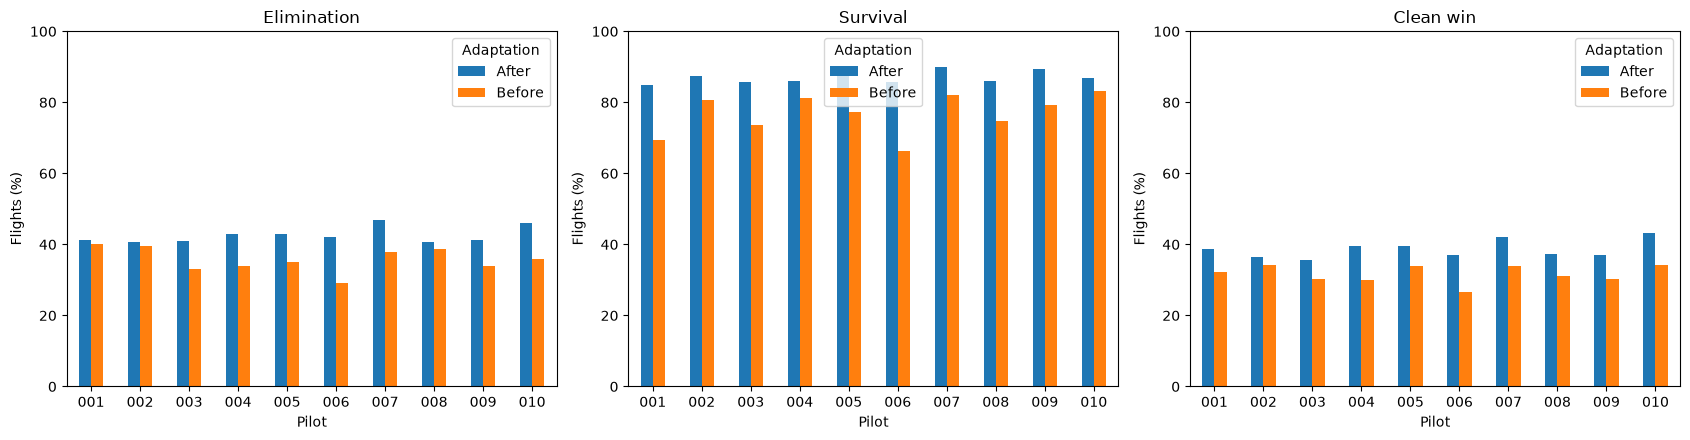

In [3]:
outcomes = []
for label, directory in (("Before", "baseline_assessment"), ("After", "adapted_assessment")):
    for file in sorted((JOB / directory).glob("*/evaluation.json")):
        result = read_json(file)
        assert result["opponent_type"] == "tactical"
        summary = result["summary"]
        outcomes.append({"population": label, "pilot": file.parent.name, "cases": summary["scenarios"],
                         **{name: summary[name] for name in ("elimination_rate", "survival_rate", "clean_win_rate", "mutual_destruction_rate",
                                                          "loss_without_elimination_rate", "outcome_score")}})
outcome_frame = pd.DataFrame(outcomes)
if outcome_frame.empty:
    print("The first tactical assessment is still running.")
else:
    rate_columns = [c for c in outcome_frame if c.endswith("_rate")]
    display(outcome_frame.style.format({**{c: "{:.1%}" for c in rate_columns}, "outcome_score": "{:.1f}"}))
    print("Available pilot counts:", outcome_frame.groupby("population")["pilot"].count().to_dict())
    display(outcome_frame.groupby("population")[rate_columns + ["outcome_score"]].mean().style.format(
        {**{c: "{:.1%}" for c in rate_columns}, "outcome_score": "{:.1f}"}))
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for ax, metric, title in zip(axes, ("elimination_rate", "survival_rate", "clean_win_rate"),
                               ("Elimination", "Survival", "Clean win")):
        chart = outcome_frame.pivot(index="pilot", columns="population", values=metric) * 100
        chart.index = chart.index.str.replace("pilot_", "", regex=False)
        chart.plot.bar(ax=ax, rot=0)
        ax.set(ylabel="Flights (%)", xlabel="Pilot", ylim=(0, 100), title=title)
        ax.legend(title="Adaptation")
    plt.tight_layout()
    plt.show()

## Learning progress

Each pilot's own reward governs its validation checkpoint selection. Rewards have different coefficients between pilots, so their raw returns do not form a common ranking. Loss measures the PPO update objective, not combat effectiveness. Unchanged validation values between evaluation epochs are carried forward.

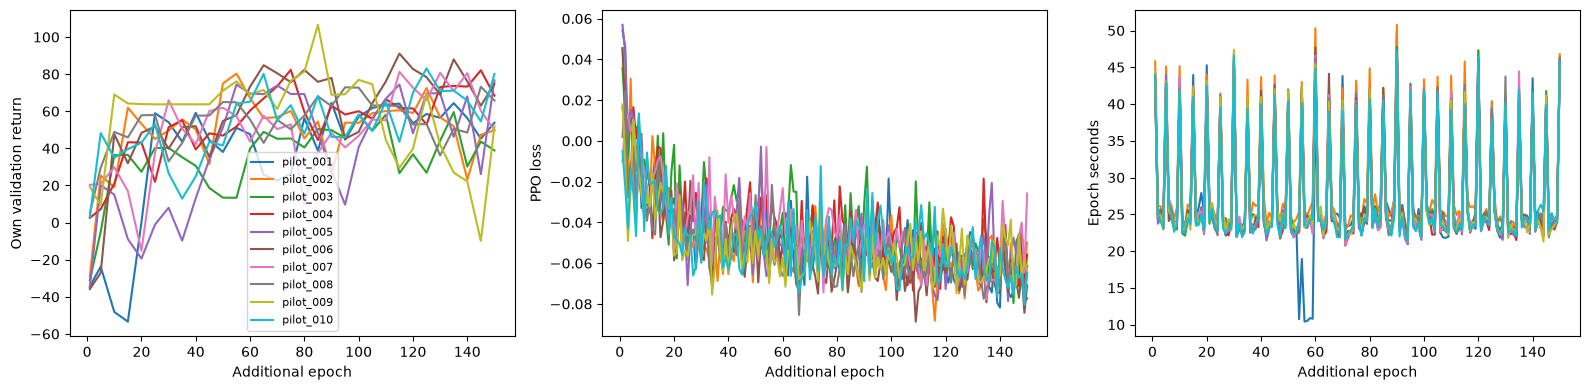

In [4]:
available = {pid: frame for pid, frame in metrics.items() if not frame.empty}
if not available:
    print("Fine-tuning starts after every pilot's starting tactical assessment is complete.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for pid, frame in available.items():
        selected = frame[frame["evaluation_performed"].eq(1)]
        axes[0].plot(selected["epoch"], selected["mean_return"], label=pid)
        axes[1].plot(frame["epoch"], frame["loss"], label=pid)
        axes[2].plot(frame["epoch"], frame["epoch_seconds"], label=pid)
    for ax, ylabel in zip(axes, ("Own validation return", "PPO loss", "Epoch seconds")):
        ax.set(xlabel="Additional epoch", ylabel=ylabel)
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## Historical paired confirmation

This archived comparison uses the same separate post-selection cases against tactical for both populations. Elimination and survival accompany clean wins in the population and per-pilot tables. Previously inspected confirmation cases cannot serve as an untouched final test. Confidence intervals describe scenario uncertainty, not variation across training seeds.

In [5]:
comparison_path = JOB / "comparison.json"
if not comparison_path.exists():
    print("Historical paired confirmation is unavailable.")
else:
    comparison = read_json(comparison_path)
    result = comparison["fresh_confirmation"]
    print("Confirmation suite:", comparison["confirmation_suite"])
    print(f"Mean clean wins: {result['baseline_mean_clean_win_rate']:.1%} before, "
          f"{result['experiment_mean_clean_win_rate']:.1%} after.")
    print(f"Change: {result['difference_percentage_points']:+.1f} percentage points.")
    print("Paired scenario bootstrap 95% interval (percentage points):",
          result["paired_scenario_bootstrap_ci95_percentage_points"])
    table = pd.DataFrame(result["pilots"]).set_index("pilot_id")
    for pid in table.index:
        before = read_json(JOB / "baseline_confirmation" / pid / "evaluation.json")["episodes"]
        after = read_json(JOB / "training" / pid / "test_episodes.json")["episodes"]
        assert [(e["seed"], e["scenario"]) for e in before] == [(e["seed"], e["scenario"]) for e in after]
        for prefix, episodes in (("baseline", before), ("experiment", after)):
            table.loc[pid, f"{prefix}_elimination_rate"] = sum(e["eliminated"] for e in episodes) / len(episodes)
    population_rows = [
        {"population": label, **{metric: table[f"{prefix}_{metric}"].mean()
         for metric in ("elimination_rate", "survival_rate", "clean_win_rate", "mutual_destruction_rate")}}
        for prefix, label in (("baseline", "Before"), ("experiment", "After"))
    ]
    display(pd.DataFrame(population_rows).set_index("population").style.format("{:.1%}"))
    ordered = [f"{prefix}_{metric}" for metric in ("elimination_rate", "survival_rate", "clean_win_rate")
               for prefix in ("baseline", "experiment")]
    table = table[ordered + [c for c in table if c not in ordered]]
    display(table.style.format({c: "{:.1%}" for c in table if c.endswith("_rate")}))
    print(result["uncertainty_note"])

Confirmation suite: {'seed': 1220000, 'scenarios': 100}
Mean clean wins: 32.7% before, 38.6% after.
Change: +5.9 percentage points.
Paired scenario bootstrap 95% interval (percentage points): [1.1974999999999996, 11.00249999999999]


,elimination_rate,survival_rate,clean_win_rate,mutual_destruction_rate
population,,,,
Before,41.8%,75.1%,32.7%,9.1%
After,48.6%,83.8%,38.6%,10.0%


,baseline_elimination_rate,experiment_elimination_rate,baseline_survival_rate,experiment_survival_rate,baseline_clean_win_rate,experiment_clean_win_rate,scenarios,difference_percentage_points,gained_clean_wins,lost_clean_wins,baseline_mutual_destruction_rate,experiment_mutual_destruction_rate
pilot_id,,,,,,,,,,,,
pilot_001,42.0%,45.0%,72.0%,81.0%,34.0%,34.0%,100,0.000000,7,7,8.0%,11.0%
pilot_002,45.0%,49.0%,75.0%,84.0%,32.0%,38.0%,100,6.000000,10,4,13.0%,11.0%
pilot_003,41.0%,46.0%,74.0%,85.0%,32.0%,37.0%,100,5.000000,13,8,9.0%,9.0%
pilot_004,42.0%,49.0%,79.0%,84.0%,33.0%,39.0%,100,6.000000,12,6,9.0%,10.0%
pilot_005,38.0%,52.0%,74.0%,86.0%,31.0%,44.0%,100,13.000000,14,1,7.0%,8.0%
pilot_006,37.0%,49.0%,65.0%,83.0%,30.0%,39.0%,100,9.000000,12,3,7.0%,10.0%
pilot_007,43.0%,51.0%,80.0%,85.0%,33.0%,43.0%,100,10.000000,12,2,10.0%,8.0%
pilot_008,51.0%,50.0%,76.0%,83.0%,37.0%,38.0%,100,1.000000,9,8,14.0%,12.0%
pilot_009,41.0%,44.0%,76.0%,85.0%,34.0%,35.0%,100,1.000000,8,7,7.0%,9.0%


Scenarios resampled jointly across pilots; training-seed variation is not measured.
